# 02 · Evaluation: does it answer correctly, and does it know when not to?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/hr-tech/hr-policy-rag-assistant/notebooks/02_evaluation.ipynb)

93 hand-written questions, phrased the way employees ask. 77 have an answer in the policies, each
with the passage it should cite and the facts the answer must contain. The other 16 should be
declined: 10 are out of scope, and 6 ask for restricted content with a role that may not see it.
Half the questions are a dev split, used for every design choice and for the decline threshold.
The other half are a test split, reported only.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "hr-tech/hr-policy-rag-assistant"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "hrrag").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: hr-policy-rag-assistant


In [2]:
from hrrag.config import Settings
from hrrag.corpus import load
from hrrag.retrieval import Retriever, visible
from hrrag.answer import Assistant

passages = load(Path("policies"))
retriever = Retriever(passages, "hybrid")
assistant = Assistant(retriever, Settings())
print(f"{len(passages)} passages from {len({p.policy_id for p in passages})} policies")
from hrrag import evaluate as E
gold = E.gold()
gold.sample(6, random_state=2)[["question", "role", "expected", "must_include", "split"]]

52 passages from 13 policies


,question,role,expected,must_include,split
36,Is remote work from outside the EU allowed?,employee,HR-05#working-from-another-country,[not permitted],test
28,Sunday work Zuschlag?,employee,HR-04#allowance-rates,[50 percent],test
54,Is a course during work hours counted as working time?,employee,HR-08#approval,[counts as working time],dev
23,what's the max hours per day including Überstunden,employee,HR-03#overtime,[10 hours],test
16,"I got sick on vacation, do I lose those leave days?",employee,HR-02#illness-during-annual-leave,[credited back],dev
77,What is the merit budget for 2026?,employee,NaN,[],dev


## Retrievers

BM25 (keywords), TF-IDF on words and character n-grams, and a hybrid of both by reciprocal rank
fusion, each with and without synonym expansion. The hybrid with synonyms was chosen on dev.
On the test split the variants are within one or two questions of each other.

In [3]:
pd.concat({"dev": E.ablation(passages, gold, "dev"), "test": E.ablation(passages, gold, "test")}).round(3)

retriever  synonyms  hit_at_1  hit_at_3    mrr  answer_correct
dev  0      bm25     False     0.775     0.925  0.863           0.750
     1      bm25      True     0.825     0.950  0.893           0.800
     2     tfidf     False     0.825     0.950  0.884           0.800
     3     tfidf      True     0.850     0.975  0.909           0.825
     4    hybrid     False     0.825     0.950  0.888           0.800
     5    hybrid      True     0.850     0.975  0.913           0.825
test 0      bm25     False     0.730     0.919  0.822           0.703
     1      bm25      True     0.703     0.946  0.823           0.676
     2     tfidf     False     0.730     0.919  0.826           0.703
     3     tfidf      True     0.757     0.946  0.853           0.730
     4    hybrid     False     0.730     0.919  0.817           0.703
     5    hybrid      True     0.730     0.946  0.835           0.703

## When to say "I don't know"

The assistant declines when its best passage scores below a threshold. Too low, and it answers
questions it should not; too high, and it refuses questions it could answer. The threshold is
chosen on dev.

threshold: 0.17


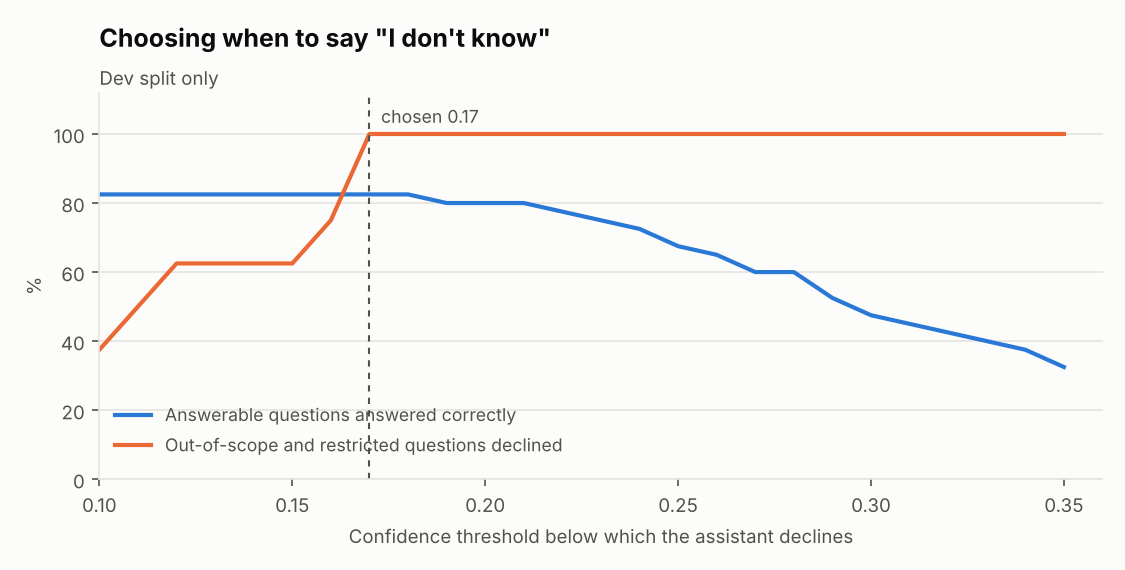

In [4]:
f = E.full(passages)
print("threshold:", f["threshold"])
display(Image("outputs/figures/decline_threshold.png"))

## Results on held-out questions

In [5]:
pd.DataFrame({"test": f["test"], "dev": f["dev"]}).round(3)

,test,dev
questions,45.000,48.000
answerable,37.000,40.000
should_decline,8.000,8.000
hit_at_1,0.730,0.850
hit_at_3,0.946,0.975
mrr,0.835,0.913
answer_correct,0.703,0.825
answer_cites_expected,0.757,0.825
wrongly_declined,0.027,0.050
decline_rate_when_should,1.000,1.000


The gap between dev and test, 83% against 70% correct answers, is why the test split exists:
it is the more honest number. The CI pipeline fails if test performance drops below 65% correct
answers, 90% top-3 retrieval or 95% correct refusals, or if a single restricted passage is cited.

## Where it goes wrong

In most misses the right passage is ranked second or third. An LLM that reads all four retrieved
passages, or a reranker, should fix many of them, since the right passage is in the top 3 for
95% of test questions.

In [6]:
r = f["results"]
r.query("split == 'test' and should_answer and not (answered and cited_expected)")[["question", "expected", "rank", "citations"]]

,question,expected,rank,citations
5,Can I take leftover vacation days into next year?,HR-01#carry-over,2.0,HR-01#entitlement
9,Is there paid leave when a parent dies?,HR-01#special-leave,5.0,HR-07#company-top-up-for-partners
11,Do I have to tell my boss what illness I have?,HR-02#reporting-sick,3.0,HR-02#illness-during-annual-leave
13,Do I have to send the Krankmeldung paper to HR myself?,HR-02#medical-certificate,3.0,HR-02#illness-during-annual-leave
19,How long is the break on a shift?,HR-03#regular-working-time,2.0,HR-10#how-long-we-keep-it
34,Can people in logistics do home office?,HR-05#who-can-work-remotely,2.0,HR-05#availability
62,Does HR store my diagnosis when I'm sick?,HR-10#what-we-process,2.0,
66,How fast will I hear back after a whistleblower report?,HR-11#what-happens-next,3.0,HR-11#how-to-report
68,Can I get in trouble for reporting a safety problem?,HR-11#protection,5.0,HR-11#what-to-report
